# 1. Project Overview & Business Objective

## 1.1 Introduction

User retention is a critical strategic priority for Waze. Maintaining a healthy, active user base directly preserves platform utility, traffic reporting density, and long-term ecosystem value. This project tackles the challenge of **predicting user churn** to help product and data teams mitigate customer attrition before it occurs.

**Project Objectives:**
* **Predictive Modeling:** Develop, tune, and evaluate supervised classification models (comparing a baseline Logistic Regression model against an ensemble Random Forest model) to predict user churn.
* **Behavioral Insight Discovery:** Identify the underlying usage patterns—such as active days, driving frequency, and intensity—that separate retained users from those who abandon the application.
* **Actionable Strategy:** Translate model coefficients and feature importances into concrete, data-backed recommendations for targeted user re-engagement campaigns.

## 1.2 Environment Setup & Data Loading

In [155]:
# Data manipulation & numerical processing
import pandas as pd
import numpy as np
from pathlib import Path

# Visualization packages
import seaborn as sns
import matplotlib.pyplot as plt

# Statistics/Regression Packages
from scipy import stats
import statsmodels.api as sm
from statsmodels.formula.api import ols
from statsmodels.stats.multicomp import pairwise_tukeyhsd

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

pd.set_option('display.max_columns', None)

DATA_PATH = Path('waze_dataset.csv')
tiktok_data = pd.read_csv(DATA_PATH)
df = tiktok_data.copy()

# 2. Data Cleaning & Missing Value Audit

## 2.1 Initital Exploration - Feature Selection & Renaming

In [156]:
df.head(10)

,ID,label,sessions,drives,total_sessions,n_days_after_onboarding,total_navigations_fav1,total_navigations_fav2,driven_km_drives,duration_minutes_drives,activity_days,driving_days,device
0,0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android
1,1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone
2,2,retained,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,Android
3,3,retained,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,iPhone
4,4,retained,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,Android
5,5,retained,113,103,279.544437,2637,0,0,901.238699,439.101397,15,11,iPhone
6,6,retained,3,2,236.725314,360,185,18,5249.172828,726.577205,28,23,iPhone
7,7,retained,39,35,176.072845,2999,0,0,7892.052468,2466.981741,22,20,iPhone
8,8,retained,57,46,183.532018,424,0,26,2651.709764,1594.342984,25,20,Android
9,9,churned,84,68,244.802115,2997,72,0,6043.460295,2341.838528,7,3,iPhone


In [157]:
# Drop 'ID' column as it is not needed for analysis
df.drop(columns=['ID'], inplace=True)

In [158]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14999 entries, 0 to 14998
Data columns (total 12 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   label                    14299 non-null  str    
 1   sessions                 14999 non-null  int64  
 2   drives                   14999 non-null  int64  
 3   total_sessions           14999 non-null  float64
 4   n_days_after_onboarding  14999 non-null  int64  
 5   total_navigations_fav1   14999 non-null  int64  
 6   total_navigations_fav2   14999 non-null  int64  
 7   driven_km_drives         14999 non-null  float64
 8   duration_minutes_drives  14999 non-null  float64
 9   activity_days            14999 non-null  int64  
 10  driving_days             14999 non-null  int64  
 11  device                   14999 non-null  str    
dtypes: float64(3), int64(7), str(2)
memory usage: 1.4 MB


*Note:* 700 missing values in the `label` feature, to be inspected. 

In [159]:
# Clean column names 

col_dict = {
    'n_days_after_onboarding': 'days_onboarded', 
    'total_navigations_fav1': 'fav_nav1', 
    'total_navigations_fav2': 'fav_nav2',
    'driven_km_drives': 'km_driven', 
    'duration_minutes_drives': 'duration_mins'
}

df.rename(columns=col_dict, inplace=True)

## 2.2 Missing Values Investigation

**Data Integrity Note:** A total of 700 vallues were identified in the `label` column. To ensure data quality, these instances must be isolated and evaluated to determine whether the missingness occurs **Missing Completely At Random (MCAR)**. 

In [160]:
df.isna().sum()

label             700
sessions            0
drives              0
total_sessions      0
days_onboarded      0
fav_nav1            0
fav_nav2            0
km_driven           0
duration_mins       0
activity_days       0
driving_days        0
device              0
dtype: int64

In [161]:
# Create DataFrames to compare side-by-side
missing_label_df = df[df['label'].isna()]
not_missing_label_df = df[df['label'].notna()]

# Compare summary statistics of the two DataFrames
print(missing_label_df.describe().T[['mean', 'std', '50%']])
print(not_missing_label_df.describe().T[['mean', 'std', '50%']])

                       mean          std          50%
sessions          80.837143    79.987440    56.000000
drives            67.798571    65.271926    47.500000
total_sessions   198.483348   140.561715   177.255925
days_onboarded  1709.295714  1005.306562  1650.500000
fav_nav1         118.717143   156.308140    62.500000
fav_nav2          30.371429    46.306984    10.000000
km_driven       3935.967029  2443.107121  3421.156721
duration_mins   1795.123358  1419.242246  1414.966279
activity_days     15.382857     8.772714    15.000000
driving_days      12.125714     7.626373    12.000000
                       mean          std          50%
sessions          80.623820    80.736502    56.000000
drives            67.255822    65.947295    48.000000
total_sessions   189.547409   136.189764   158.718571
days_onboarded  1751.822505  1008.663834  1749.000000
fav_nav1         121.747395   147.713428    71.000000
fav_nav2          29.638296    45.350890     9.000000
km_driven       4044.401535 

Distribution of values are roughly identical, pointing towards MCAR. 

In [162]:
# Check Categoirical Variables: To determine if missingness aligns with specific device type. 
print(missing_label_df['device'].value_counts(normalize=True))
print(not_missing_label_df['device'].value_counts(normalize=True))

device
iPhone     0.638571
Android    0.361429
Name: proportion, dtype: float64
device
iPhone     0.64515
Android    0.35485
Name: proportion, dtype: float64


iPhone vs. Android breakdown is even at approximmately 65%/35%, indicating that device type is not driving the missing data. 

**Recommendation:** Drop rows where `label` is missing, as there is no evidence of a cause for the missingness, thus we can assume MCAR.

In [163]:
df.dropna(subset=['label'], inplace=True)

#### Missing Values Analysis Findings
The purpose of this analysis is to build a model to predict user churn, thus the ultimate target variable is `label`. The presence of nulls in this column lacks the ground truth necessary for supervised learning, for the following reasons:
- **Supervised Models Need Labels:** Machine learning algorithms, (e.g. logistic regression, random forests, XGBoost) learn by comparing their predictions against known outcomes during training. A row without a label provides no signal for loss calculation or metric evaluation (precision, accurary, recall, AUC-ROC).
- **Imputation is Counterproductive:** Trying to guess or impute missing target labels introduces artificial bias into the model, essentially teaching it to predict synthetic assumptions rather than real user behavior. 
- **MCAR Findings Validates Deletion:** A comparison of numerical distributions (means, medians, standard deviations) and categorical proportions (`device`) between the null and non-null subsets revealed no systematic differences. This indicates the missing values in the `label` column occur **Missing Completely at Random (MCAR)**. Consequently, all 700 rows with missing labels were safely removed via listwise deletion, leaving a clean dataset for statistical analysis and modeling.

#### Proposed Leveraging of Null Rows Later
- **Unsupervised Clustering:** Potential to run algorithms such as K-Means on the full dataset (including the missing label rows) to discover natural user segments based on driving habits and engagement patterns.
- **Pseudo-Labeling / Semi-Supervised Learning:** Given the production of a highly reliable model, could pass these unlabeled rows through the model to predict their churn possibilites for business strategy or segment analysis. 

## 2.3 Outlier Investigation

In [164]:
df.describe().T[['std', 'min', '25%', '50%', 'mean', '75%', 'max']]

,std,min,25%,50%,mean,75%,max
sessions,80.736502,0.000000,23.000000,56.000000,80.623820,111.000000,743.000000
drives,65.947295,0.000000,20.000000,48.000000,67.255822,93.000000,596.000000
total_sessions,136.189764,0.220211,90.457733,158.718571,189.547409,253.540450,1216.154633
days_onboarded,1008.663834,4.000000,878.500000,1749.000000,1751.822505,2627.500000,3500.000000
fav_nav1,147.713428,0.000000,10.000000,71.000000,121.747395,178.000000,1236.000000
fav_nav2,45.350890,0.000000,0.000000,9.000000,29.638296,43.000000,415.000000
km_driven,2504.977970,60.441250,2217.319909,3496.545617,4044.401535,5299.972162,21183.401890
duration_mins,1448.005047,18.282082,840.181344,1479.394387,1864.199794,2466.928876,15851.727160
activity_days,9.016088,0.000000,8.000000,16.000000,15.544653,23.000000,31.000000
driving_days,7.833835,0.000000,5.000000,12.000000,12.182530,19.000000,30.000000


*Note:* Several key numerical features exhibit means that are substantially higher than their respective means, including:
* `sessions`
* `drives`
* `total_sessions`
* `fav_nav1`
* `fav_nav2`
* `km_driven`
* `duration_mins`

This right-skewed pattern indicates the presence of high-value outliers representing heavy app usage.

**Recomendation:** Applying robust scaling, log transformations, or non-parametric evaluation is necessary before feeding these features into distance-sensitive models.

### IQR Analysis

In [165]:
def get_outlier_count(df, column):
    """
    Calculates IQR bounds and returns the count and percentage of outliers for a column.
    """
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[column] < lower_bound) | (df[column] > upper_bound)]
    count = len(outliers)
    percentage = round((count / len(df)) * 100, 2)
    
    return count, percentage

In [166]:
def summarize_outliers(df, columns):
    """
    Generates a summary DataFrame showing outlier counts and percentages for a list of features.
    """
    summary_data = []
    
    for col in columns:
        count, pct = get_outlier_count(df, col)
        summary_data.append({
            'Feature': col,
            'Outlier Count': count,
            'Percentage (%)': round(pct, 2)
        })
        
    return pd.DataFrame(summary_data)

In [167]:
# List of numerical features to evaluate
numeric_features = [
    'sessions', 'drives', 'total_sessions', 'days_onboarded', 
    'fav_nav1', 'fav_nav2', 'km_driven', 'duration_mins', 
    'activity_days', 'driving_days'
]
# Get summary table
summarize_outliers(df, numeric_features)

,Feature,Outlier Count,Percentage (%)
0,sessions,709,4.96
1,drives,695,4.86
2,total_sessions,500,3.50
3,days_onboarded,0,0.00
4,fav_nav1,682,4.77
5,fav_nav2,976,6.83
6,km_driven,440,3.08
7,duration_mins,613,4.29
8,activity_days,0,0.00
9,driving_days,0,0.00


**Outlier Investigation Focus:** Based on the IQR threshold analysis, initial investigation will prioritize **`sessions`** (4.96% outliers), **`drives`** (4.86%), **`duration_mins`** (4.29%), and **`km_driven`** (3.08%). These four core engagement metrics account for the vast majority of extreme upper-bound values in the dataset. Analyzing their distributions together will help determine if power-user activity is driven by long distance/duration trips or frequent short-session app interactions, providing critical context for modeling churn behavior.

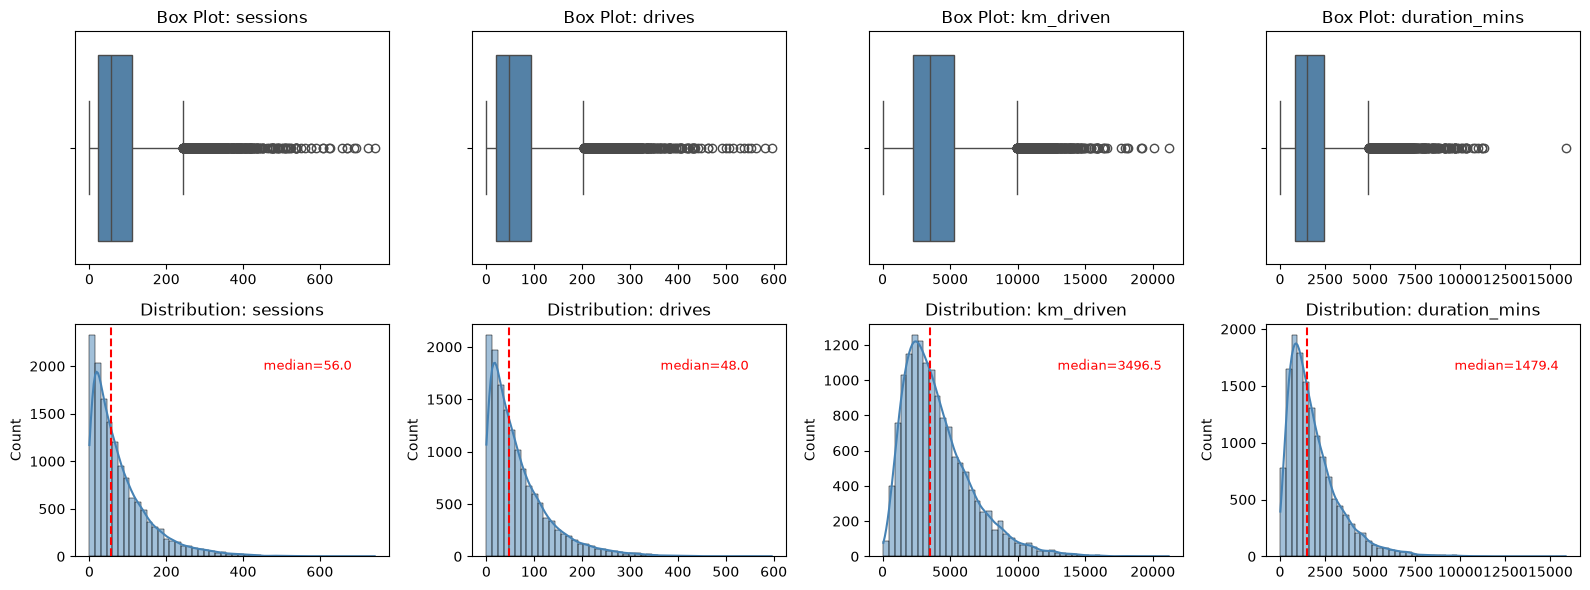

In [168]:
# Define the 4 core engagement metrics
core_eng_metrics = ['sessions', 'drives', 'km_driven', 'duration_mins']

# Create a 2x4 grid (2 rows: row 1 for boxplots, row 2 for histograms; 4 columns for the 4 metrics)
fig, axes = plt.subplots(2, 4, figsize=(16, 6))

for i, col in enumerate(core_eng_metrics):
    # 1. Box Plot (Top Row)
    sns.boxplot(x=df[col], ax=axes[0, i], color='steelblue')
    axes[0, i].set_title(f'Box Plot: {col}')
    axes[0, i].set_xlabel('')

    # 2. Histogram with KDE & Median Line (Bottom Row)
    ax = sns.histplot(df[col], bins=50, kde=True, ax=axes[1, i], color='steelblue')
    median = round(df[col].median(), 1)
    
    # Add vertical line for the median
    axes[1, i].axvline(median, color='red', linestyle='--')
    
    # Add text annotation for the median
    ax.text(0.60, 0.85, f'median={median}', color='red', 
            ha='left', va='top', transform=ax.transAxes, fontsize=9)
    
    axes[1, i].set_title(f'Distribution: {col}')
    axes[1, i].set_xlabel('')

plt.tight_layout()
plt.show()

#### Outlier Analysis Findings
* **Severe Right-Skewness:** All four core engagement metrics (sessions, drives, km_driven, and duration_mins) exhibit strong right-skewness, with means consistently pulling higher than their respective medians.
* **Power-User Outliers:** Box plots and histograms reveal extensive upper tails and high-value outliers representing extreme power-user activity (e.g., sessions extending up to 700+, drives up to 600, and distances surpassing 20,000 km).   
* **Modeling Implication:** Because these extreme values reflect legitimate high-engagement behavior rather than data entry errors, robust scaling, capping, or logarithmic transformations are required prior to downstream model training. 

# 3. Exploratory Data Analysis & Feature Engineering

## 3.1 Segmentation Analysis: `label`

### 3.1.1 Class Balance Check

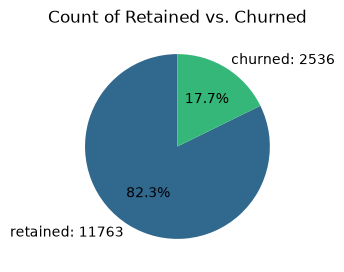

In [169]:
fig = plt.figure(figsize=(3,3))
data=df['label'].value_counts()
plt.pie(data, 
        labels=[f'{data.index[0]}: {data.values[0]}', 
                f'{data.index[1]}: {data.values[1]}'],
        autopct='%1.1f%%',
        colors=sns.color_palette('viridis', len(data)), 
        startangle=90
        )
plt.title('Count of Retained vs. Churned');

* **Class Imbalance Identified:** The target variable (label) exhibits a moderate class imbalance, with retained users accounting for 82.3% (11,763 records) and churned users representing 17.7% (2,536 records) of the dataset.   
* **Modeling Implication:** Because the minority class (churned) makes up less than 20% of the total data, standard accuracy metrics will be misleading. Downstream model evaluation should prioritize precision, recall, F1-score, or ROC-AUC, and resampling techniques (such as SMOTE) or class-weight adjustments should be considered during training.

### 3.1.2 Engagement by Churn Status

In [170]:
# Calculate median values of all columns for churned and retained users
df.groupby('label').median(numeric_only=True).T

label,churned,retained
sessions,59.000000,56.000000
drives,50.000000,47.000000
total_sessions,164.339042,157.586756
days_onboarded,1321.000000,1843.000000
fav_nav1,84.500000,68.000000
fav_nav2,11.000000,9.000000
km_driven,3652.655666,3464.684614
duration_mins,1607.183785,1458.046141
activity_days,8.000000,17.000000
driving_days,6.000000,14.000000


**Key Insights — Churned vs. Retained Median Engagement Profile:**

* **Higher Intensity Driving Among Churned Users:** Churned users exhibited greater overall driving intensity in their final active month, logging higher medians in monthly sessions (**59.0** vs. **56.0**), total drives (**50.0** vs. **47.0**), and distance driven (**3,652.7 km** vs. **3,464.7 km**) compared to retained users.
* **Compressed Activity Window (Behavioral Red Flag):** Despite driving more distance and logging more sessions, churned users logged significantly fewer active days (**8.0 activity days** vs. **17.0**) and fewer driving days (**6.0 driving days** vs. **14.0**). This reveals that churned users concentrate heavy driving usage into brief, high-density periods before abruptly dropping off.
* **Tenure Difference:** Retained users have a substantially higher median onboarding tenure (**1,843 days** / ~5 years) compared to churned users (**1,321 days** / ~3.6 years), indicating long-term user stability once a user passes early tenure milestones.

## 3.2 Feature Transformation

"Note: For linear models, we apply log transformations to handle right-skewness. For tree-based models (Random Forest/XGBoost), we utilize the original features as tree algorithms are invariant to monotonic transformations."

In [171]:
# Transform skewed features using log transformation to reduce skewness and improve normality
skewed_cols = ['sessions', 'drives', 'km_driven', 'duration_mins', 'total_sessions', 'fav_nav1', 'fav_nav2']

for col in skewed_cols:
    df[f'{col}_log'] = np.log1p(df[col])

df.head()

,label,sessions,drives,total_sessions,days_onboarded,fav_nav1,fav_nav2,km_driven,duration_mins,activity_days,driving_days,device,sessions_log,drives_log,km_driven_log,duration_mins_log,total_sessions_log,fav_nav1_log,fav_nav2_log
0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,Android,5.648974,5.424950,7.874680,7.594268,5.696248,5.342334,0.000000
1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,iPhone,4.897840,4.682131,9.526385,8.058793,5.792698,2.995732,4.174387
2,retained,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,Android,4.744932,4.564348,8.026219,7.385067,4.916493,0.000000,0.000000
3,retained,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,iPhone,3.912023,3.713572,6.818477,6.377061,4.228135,5.777652,2.079442
4,retained,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,Android,4.442651,4.234107,8.281775,7.107062,5.131359,5.117994,1.791759


## 3.3 Feature Extraction

In this section we'll explore some additional engagement metrics by extracting new features from the originals. 

### 3.3.1 `professional_driver`

These parameters were chosen to capture users who rely on the app frequently—averaging multiple trips per day over at least half the month, which is characteristic of daily commuters or gig workers.

In [172]:
# Create a professional_driver column  
df['professional_driver'] = np.where((df['drives'] >= 60) & (df['driving_days'] >= 15), 1, 0)

# Check counts of professional and non-professional drivers
df['professional_driver'].value_counts()

# Group by professional_driver and label to see churn distribution
df.groupby(['professional_driver'])['label'].value_counts(normalize=True)

professional_driver  label   
0                    retained    0.801202
                     churned     0.198798
1                    retained    0.924437
                     churned     0.075563
Name: proportion, dtype: float64

#### Driver Classification (`professional_driver`) Churn Dynamics

* **Significant Retention Advantage:** Professional drivers exhibit a low **7.6% churn rate**, compared to a **19.9% churn rate** among non-professional drivers—making non-professionals **~2.6× more likely to churn**.
* **High Utility Alignment:** Strong retention among high-mileage users points to excellent core utility and high platform dependency for heavy/commercial driving needs.
* **Predictive Signal:** The high variance in churn rates between driver types indicates that `professional_driver` will serve as a high-value predictive feature for downstream classification algorithms.
* **Targeted Strategy:** Re-engagement campaigns should focus primarily on non-professional drivers to curb the majority of user attrition, while protecting feature stability for power users.

### 3.3.2 `km_per_drive`

In [173]:
# Add a column to df called 'km_per_drive'
df['km_per_drive'] = df['km_driven'] / df['drives']

# Group by 'label', calculate the median, and isolate for km per drive
median_km_per_drive = df.groupby('label').median(numeric_only=True)[['km_per_drive']]
median_km_per_drive

,km_per_drive
label,
churned,74.109416
retained,75.014702


The retained user median km per drive is approximately one more kilometer per drive than the median churned user. How many kilometers per driving day was this?

### 3.3.3 `km_per_driving_day`

In [174]:
df['km_per_driving_day'] = df['km_driven'] / df['driving_days']

median_km_per_driving_day = df.groupby('label').median(numeric_only=True)[['km_per_driving_day']]
print(median_km_per_driving_day)
print()
print(df['km_per_driving_day'].describe())

          km_per_driving_day
label                       
churned           697.541999
retained          289.549333

count    1.429900e+04
mean              inf
std               NaN
min      3.022063e+00
25%      1.675616e+02
50%      3.241789e+02
75%      7.608293e+02
max               inf
Name: km_per_driving_day, dtype: float64


c:\Users\Owner\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\pandas\core\nanops.py:1028: RuntimeWarning: invalid value encountered in subtract
  sqr = _ensure_numeric((avg - values) ** 2)


Infinite values are present due to there being values of 0 in the `driving_days` column, in which Pandas imputes a value of infinity in the corresponding rows of the new column because division by 0 is undefined. 

In [175]:
# Convert infinite values to zero
df.loc[df['km_per_driving_day'] == np.inf, 'km_per_driving_day'] = 0

# Confirm that it worked
df['km_per_driving_day'].describe()

count    14299.000000
mean       581.942399
std       1038.254509
min          0.000000
25%        136.168003
50%        273.301012
75%        558.018761
max      15420.234110
Name: km_per_driving_day, dtype: float64

The maximum value for km_per_driving_day of 15420 seems highly unlikely, suggesting the presence of extreme outliers or data entry anomalies that may require capping or filtering before downstream modeling.

### 3.3.4 `drives_per_driving_day`

In [176]:
df['drives_per_driving_day'] = df['drives'] / df['driving_days']

median_drives_per_driving_day = df.groupby('label').median(numeric_only=True)[['drives_per_driving_day']]
median_drives_per_driving_day

,drives_per_driving_day
label,
churned,10.0000
retained,4.0625


### 3.3.5 `speed_kmh`

In [177]:
# Compute implied average speed in k/hr
df['speed_kmh'] = df['km_driven'] / (df['duration_mins'] / 60)

# Display summary statistics to inspect the distribution 
df['speed_kmh'].describe()

count    14299.000000
mean       190.730963
std        339.926138
min         72.013095
25%         90.649402
50%        122.105845
75%        193.238449
max      23642.920871
Name: speed_kmh, dtype: float64

In [178]:
# Inspect users with extreme or impossible speeds (>150km/h)
unrealistic_speeds = df[df['speed_kmh'] > 150]
print(f'Users with implied speed > 150km/h: {len(unrealistic_speeds)} ({len(unrealistic_speeds) / len(df):.2%})')

Users with implied speed > 150km/h: 5300 (37.07%)


Having 37% of the dataset reporting implied speeds over 150 km/h, and reaching maximums over 23,000 km/h, strongly suggests either a systematic data tracking anomaly, unit mismatch, or synthetic generation artifact. 

## 3.4 Data Integrity & Synthetic Artifact Audit

During previous EDA, we cross-referenced monthly driving distance (`km_driven`) against trip duration (`duration_mins`) to evaluate average travel speeds. 

**Key Finding:** 
Calculating monthly distance over duration yields heavily unrealistic implied travel speeds, with over 37% of the cohort logging average speeds exceeding 150 km/h (and extreme values surpassing 23,000 km/h). Testing alternative scale units (such as seconds vs. minutes) confirmed this is not a unit mismatch. 

**Analytical Implication:** 
This indicates that the dataset contains synthetic generation artifacts where total distance and duration were generated independently without enforcing real-world physical constraints ($\text{Distance} = \text{Speed} \times \text{Time}$). Consequently, we will **exclude derived speed ratios** from our feature set to prevent introducing synthetic noise into downstream machine learning models.

In [179]:
# Quick audit verifying the synthetic artifact anomaly for documentation purposes
df['speed_kmh'] = df['km_driven'] / (df['duration_mins'] / 60)

unrealistic_count = (df['speed_kmh'] > 150).sum()
pct_unrealistic = (unrealistic_count / len(df)) * 100

print(f"Total Records Evaluated: {len(df):,}")
print(f"Records with Implied Speed > 150 km/h: {unrealistic_count:,} ({pct_unrealistic:.2f}%)")
print(f"Maximum Implied Speed Observed: {df['speed_kmh'].max():,.1f} km/h")

Total Records Evaluated: 14,299
Records with Implied Speed > 150 km/h: 5,300 (37.07%)
Maximum Implied Speed Observed: 23,642.9 km/h


## 3.5 Categorical Feature Encoding

In [180]:
# Convert the 'device' categorical variable into dummy variables for modeling (Android: 0, iPhone: 1)
df['device'] = pd.get_dummies(df['device'], drop_first=True, dtype=int)
df.head()

,label,sessions,drives,total_sessions,days_onboarded,fav_nav1,fav_nav2,km_driven,duration_mins,activity_days,driving_days,device,sessions_log,drives_log,km_driven_log,duration_mins_log,total_sessions_log,fav_nav1_log,fav_nav2_log,professional_driver,km_per_drive,km_per_driving_day,drives_per_driving_day,speed_kmh
0,retained,283,226,296.748273,2276,208,0,2628.845068,1985.775061,28,19,0,5.648974,5.424950,7.874680,7.594268,5.696248,5.342334,0.000000,1,11.632058,138.360267,11.894737,79.430298
1,retained,133,107,326.896596,1225,19,64,13715.920550,3160.472914,13,11,1,4.897840,4.682131,9.526385,8.058793,5.792698,2.995732,4.174387,0,128.186173,1246.901868,9.727273,260.389902
2,retained,114,95,135.522926,2651,0,0,3059.148818,1610.735904,14,8,0,4.744932,4.564348,8.026219,7.385067,4.916493,0.000000,0.000000,0,32.201567,382.393602,11.875000,113.953460
3,retained,49,40,67.589221,15,322,7,913.591123,587.196542,7,3,1,3.912023,3.713572,6.818477,6.377061,4.228135,5.777652,2.079442,0,22.839778,304.530374,13.333333,93.351141
4,retained,84,68,168.247020,1562,166,5,3950.202008,1219.555924,27,18,0,4.442651,4.234107,8.281775,7.107062,5.131359,5.117994,1.791759,1,58.091206,219.455667,3.777778,194.342970


In [181]:
# Map 'retained' to 0 and 'churned' to 1
df['label_encoded'] = df['label'].map({'retained': 0, 'churned': 1})

# Verify the mapping
print(df[['label', 'label_encoded']].value_counts())

label     label_encoded
retained  0                11763
churned   1                 2536
Name: count, dtype: int64


# 4. Modeling

## 4.1 Feature Preprocessing & Evaluation Metric Establishment

#### **Why ROC-AUC as Our Primary Evaluation Metric?**
* **Invariance to Class Imbalance:** Because our target variable (`label`) suffers from class imbalance—where retained users make up **82.3%** and churned users comprise **17.7%**—standard accuracy is a misleading metric. A naive model that always predicts "retained" would achieve 82.3% accuracy while completely failing to identify a single churned user.
* **Threshold-Independent Performance:** Metrics like precision and recall depend on a strict classification threshold (typically 0.5), which can be suboptimal for imbalanced datasets. **ROC-AUC (Receiver Operating Characteristic - Area Under Curve)** evaluates the model's overall ability to discriminate between churned and retained users across *all possible classification thresholds*. 
* **Business Alignment:** ROC-AUC measures how effectively our model ranks high-risk users at the top of the probability distribution, giving Waze the flexibility to adjust intervention thresholds depending on retention campaign budgets and capacity.

In [182]:
# Define X and y for modeling
y = df['label_encoded']

# For logistic regression, we will use the following features (including the logarithmic transformations):
X_log = df[['sessions_log', 'drives_log', 'km_driven_log', 'duration_mins_log', 'fav_nav1_log', 'fav_nav2_log', 'total_sessions_log',
        'professional_driver', 'device', 'activity_days', 'driving_days', 'km_per_drive', 'km_per_driving_day', 'drives_per_driving_day']]

# For ensemble models, we can use the original features without log transformation:
X_ens = df[['sessions', 'drives', 'km_driven', 'duration_mins', 'fav_nav1', 'fav_nav2', 'total_sessions', 
        'professional_driver', 'device', 'activity_days', 'driving_days', 'km_per_drive', 'km_per_driving_day', 'drives_per_driving_day']]

In [183]:
# 1. Train/Test split for Logistic Regression (X_log)
X_train_log, X_test_log, y_train, y_test = train_test_split(
    X_log, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Train/Test split for Ensemble Models (X_ens)
X_train_ens, X_test_ens, _, _ = train_test_split(
    X_ens, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training shape: {X_train_log.shape}, Testing shape: {X_test_log.shape}")
print(f"Churn proportion in training set: {y_train.mean():.4f}")
print(f"Churn proportion in test set: {y_test.mean():.4f}")

Training shape: (11439, 14), Testing shape: (2860, 14)
Churn proportion in training set: 0.1774
Churn proportion in test set: 0.1773


In [184]:
# For Logistic Regression, we will apply StandardScaler to ensure continuous log features are on a comparable scale before training the model.
# This is important for models that are sensitive to feature scaling.

# 0. Clean infinity/NaNs from feature sets
X_log_clean = X_log.replace([np.inf, -np.inf], np.nan).fillna(0)
X_ens_clean = X_ens.replace([np.inf, -np.inf], np.nan).fillna(0)

# 1. Train/Test split for Logistic Regression
X_train_log, X_test_log, y_train, y_test = train_test_split(
    X_log_clean, y, test_size=0.2, random_state=42, stratify=y
)

# 2. Train/Test split for Ensemble Models
X_train_ens, X_test_ens, _, _ = train_test_split(
    X_ens_clean, y, test_size=0.2, random_state=42, stratify=y
)

# 3. Apply Standard Scaler to Logistic Regression sets
scaler = StandardScaler()
X_train_log_scaled = scaler.fit_transform(X_train_log)
X_test_log_scaled = scaler.transform(X_test_log)

print("Scaling and splitting completed successfully without errors!")

Scaling and splitting completed successfully without errors!


## 4.2 Logistic Regression (Baseline Model)

In [185]:
# 1. Initialize and train Logistic Regression on the scaled log features
lr_model = LogisticRegression(class_weight='balanced', random_state=42)
lr_model.fit(X_train_log_scaled, y_train)

# 2. Predict on the test set
y_pred_lr = lr_model.predict(X_test_log_scaled)
y_prob_lr = lr_model.predict_proba(X_test_log_scaled)[:, 1]

# 3. Print Evaluation Metrics
print("--- Logistic Regression Performance ---")
print(classification_report(y_test, y_pred_lr))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_lr):.4f}")

--- Logistic Regression Performance ---
              precision    recall  f1-score   support

           0       0.91      0.64      0.75      2353
           1       0.29      0.69      0.41       507

    accuracy                           0.65      2860
   macro avg       0.60      0.67      0.58      2860
weighted avg       0.80      0.65      0.69      2860

ROC-AUC Score: 0.7230


## 4.3 Random Forest (Ensemble Model)

In [186]:
# 1. Initialize and train Random Forest on the unscaled ensemble features
rf_model = RandomForestClassifier(class_weight='balanced', random_state=42, n_estimators=100)
rf_model.fit(X_train_ens, y_train)

# 2. Predict on the test set
y_pred_rf = rf_model.predict(X_test_ens)
y_prob_rf = rf_model.predict_proba(X_test_ens)[:, 1]

# 3. Print Evaluation Metrics
print("\n--- Random Forest Performance ---")
print(classification_report(y_test, y_pred_rf))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_prob_rf):.4f}")


--- Random Forest Performance ---
              precision    recall  f1-score   support

           0       0.86      0.89      0.87      2353
           1       0.38      0.32      0.35       507

    accuracy                           0.79      2860
   macro avg       0.62      0.60      0.61      2860
weighted avg       0.77      0.79      0.78      2860

ROC-AUC Score: 0.7071


## 4.4 Feature Importance & Interpretability 

### 4.4.1 Logistic Regression Coefficients (Drivers of Churn)

In [187]:
# Create a dataframe of feature coefficients
coefficients = pd.DataFrame({
    'Feature': X_train_log.columns,
    'Coefficient': lr_model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("Top Features Driving Churn (Logistic Regression):")
display(coefficients.head(10))

Top Features Driving Churn (Logistic Regression):


,Feature,Coefficient
1,drives_log,0.311828
4,fav_nav1_log,0.124910
3,duration_mins_log,0.118424
11,km_per_drive,0.094853
6,total_sessions_log,0.055097
5,fav_nav2_log,0.018923
8,device,0.013578
13,drives_per_driving_day,0.011972
12,km_per_driving_day,0.007558
7,professional_driver,0.001306


### 4.4.2 Random Forest Feature Importances 

In [188]:
# Create a dataframe of feature importances from the Random Forest
importances = pd.DataFrame({
    'Feature': X_train_ens.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=False)

print("\nTop Predictive Features (Random Forest):")
display(importances.head(10))


Top Predictive Features (Random Forest):


,Feature,Importance
9,activity_days,0.113228
12,km_per_driving_day,0.092320
10,driving_days,0.089315
3,duration_mins,0.087626
6,total_sessions,0.086166
2,km_driven,0.081363
11,km_per_drive,0.080091
4,fav_nav1,0.079801
13,drives_per_driving_day,0.075475
0,sessions,0.069064


### 4.4.3 Feature Importances Plots

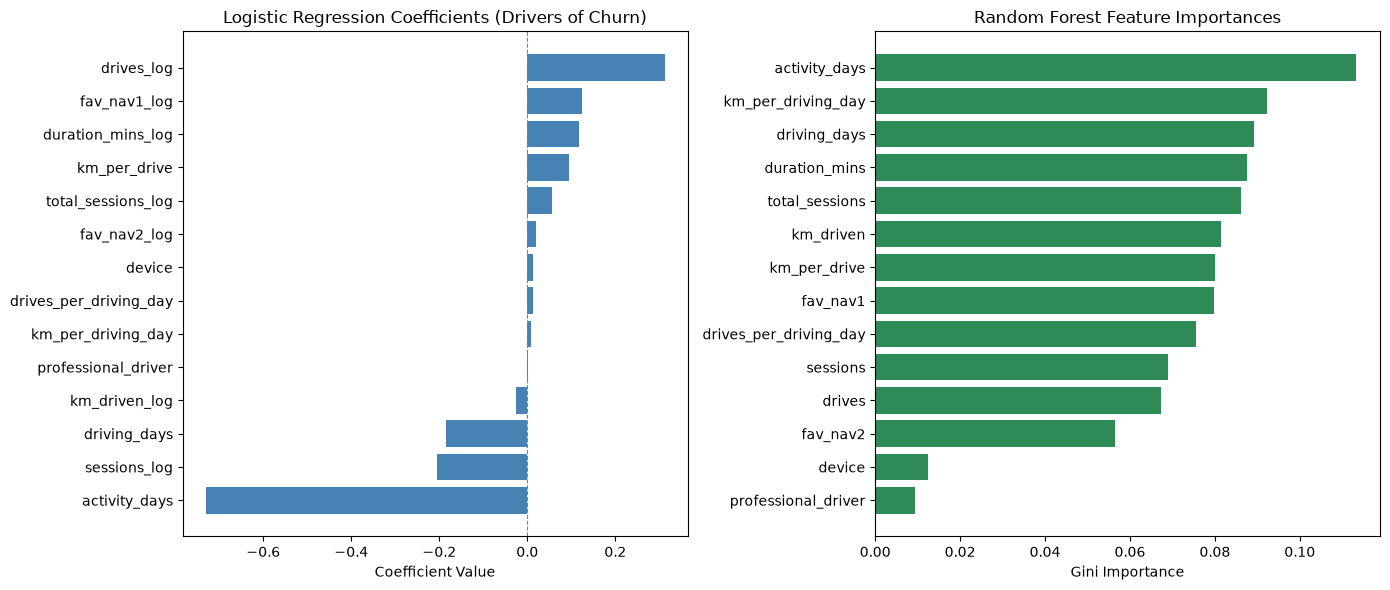

In [189]:
# Create a figure with two subplots side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# 1. Logistic Regression Coefficients Plot
coefficients = pd.DataFrame({
    'Feature': X_train_log.columns,
    'Coefficient': lr_model.coef_[0]
}).sort_values(by='Coefficient', ascending=True) # Ascending so top feature is at the top of barh

axes[0].barh(coefficients['Feature'], coefficients['Coefficient'], color='steelblue')
axes[0].set_title('Logistic Regression Coefficients (Drivers of Churn)')
axes[0].set_xlabel('Coefficient Value')
axes[0].axvline(0, color='gray', linestyle='--', linewidth=0.8)

# 2. Random Forest Feature Importances Plot
importances = pd.DataFrame({
    'Feature': X_train_ens.columns,
    'Importance': rf_model.feature_importances_
}).sort_values(by='Importance', ascending=True)

axes[1].barh(importances['Feature'], importances['Importance'], color='seagreen')
axes[1].set_title('Random Forest Feature Importances')
axes[1].set_xlabel('Gini Importance')

plt.tight_layout()
plt.show()

#### **Feature Importance & Coefficient Analysis**
* **Logistic Regression (Linear Drivers):** Highlights that total monthly trip volume (`drives_log`), frequent use of primary favorite locations (`fav_nav1_log`), and trip duration (`duration_mins_log`) are strongly associated with higher churn probability. Conversely, consistency factors like `activity_days` and `driving_days` exhibit large negative coefficients, confirming that steady, regular engagement strongly guards against churn.
* **Random Forest (Non-Linear Importances):** Ranks `activity_days`, `km_per_driving_day`, and `driving_days` as its top predictive features. This proves that temporal consistency and usage pacing are critical decision boundaries for tree-based algorithms.
* **Model Convergence:** Both models reinforce the core insight that user retention is dictated less by the absolute distance traveled and more by **how consistently** a user interacts with the application across the month.

## 4.5 Confusion Matrices

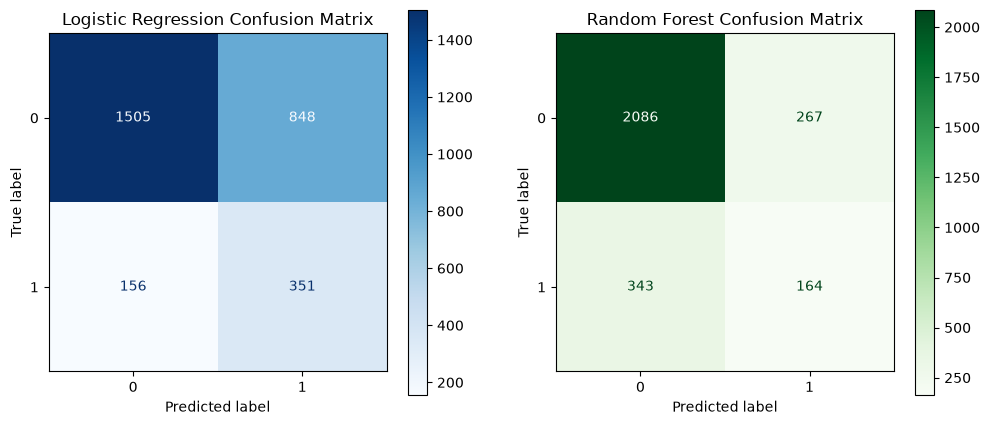

In [190]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_estimator(lr_model, X_test_log_scaled, y_test, ax=axes[0], cmap='Blues')
axes[0].set_title("Logistic Regression Confusion Matrix")

ConfusionMatrixDisplay.from_estimator(rf_model, X_test_ens, y_test, ax=axes[1], cmap='Greens')
axes[1].set_title("Random Forest Confusion Matrix")
plt.show()

#### **Confusion Matrix Performance Analysis**
* **Logistic Regression (Baseline):** Demonstrates high sensitivity (catching 351 out of 507 actual churners, yielding a **69% recall** for class 1), making it effective at flagging users at risk. However, it suffers from a high volume of false positives (848 retained users incorrectly flagged as churned), resulting in low precision. This trade-off makes it useful for a broad retention campaign where missing a churner is more costly than sending an unnecessary promotional offer.
* **Random Forest (Ensemble):** Achieves higher overall accuracy (79%) and fewer false positives (only 267 false alarms), but struggles with lower sensitivity (catching only 164 out of 507 churners, yielding a **32% recall** for churned users). 
* **Business Trade-off:** While the Random Forest is cleaner at avoiding false alarms among retained users, the Logistic Regression model performs better as a risk-detection tool because it successfully captures a significantly larger share of actual churned users under the current default threshold.

# 5. Conclusion & Strategic Recommendations

### **5.1 Summary of Modeling Insights**
Both the baseline Logistic Regression model (ROC-AUC: 0.7230) and the ensemble Random Forest model (ROC-AUC: 0.7071) demonstrated reliable predictive capability, successfully capturing the underlying behavioral signals of user attrition. Across both model interpretations, feature importances and coefficients converged on a central theme: **engagement consistency (`activity_days`, `driving_days`) and volumetric intensity (`drives_log`, `duration_mins`) are the primary determinants of retention**. 

These modeling outcomes validate our core EDA insight—that churned users do not leave due to a lack of driving need, but rather exhibit a risky pattern of erratic, high-intensity usage over compressed time windows. 

### **5.2 Strategic Recommendations for Waze**
To proactively combat user attrition and lower churn rates across the platform, Waze data and product teams should implement the following data-backed interventions:
* **Targeted Interventions:** Focus retention campaigns specifically on non-professional drivers. Non-professional users face a **19.9% churn rate**, making them **~2.6× more likely to churn** compared to professional drivers (7.6%). Tailored onboarding workflows, milestone incentives, or casual-user features can help secure their long-term habits.
* **Early-Warning Triggers:** Monitor users whose daily driving intensity spikes over a compressed window (`activity_days` narrowing while trip volume remains temporarily high). Because this erratic high-density pattern serves as a primary behavioral red flag for impending churn, automated app notifications or alternative routing check-ins can be triggered early to re-stabilize their engagement.